In [ ]:
pkgs <- c("tidyverse", "caret", "pROC", "rpart", "rpart.plot",
          "randomForest", "scales", "corrplot")
new_pkgs <- pkgs[!(pkgs %in% installed.packages()[, "Package"])]
if (length(new_pkgs) > 0) install.packages(new_pkgs, repos = "https://cloud.r-project.org")
invisible(lapply(pkgs, library, character.only = TRUE))
options(repr.plot.width = 9, repr.plot.height = 5)
cat("Packages loaded\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘recipes’, ‘reshape2’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: lattice


Attaching package: ‘caret’


Th

Packages loaded


In [ ]:
set.seed(123)
dir.create("data",   showWarnings = FALSE)
dir.create("charts", showWarnings = FALSE)

if (!file.exists("data/bank-full.csv")) {
  tryCatch({
    download.file("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                  destfile = "data/bank_marketing.zip", mode = "wb")
    unzip("data/bank_marketing.zip", exdir = "data")
    unzip("data/bank.zip", exdir = "data")
  }, error = function(e) message("Download failed: ", conditionMessage(e)))
}
if (!file.exists("data/bank-full.csv"))
  stop("bank-full.csv not found. Upload it into the 'data' folder (Files panel) and rerun.")

bank_raw <- read.csv("data/bank-full.csv", sep = ";", stringsAsFactors = FALSE)
head(bank_raw)

cat("Records:", nrow(bank_raw), "\n")
cat("Input features:", ncol(bank_raw) - 1, "(+ target y)\n\n")
str(bank_raw)
summary(bank_raw)

cat("Missing values (NA):", sum(is.na(bank_raw)), "\n")
cat("Duplicate rows     :", sum(duplicated(bank_raw)), "\n")
cat("pdays = -1 (not contacted before):", sum(bank_raw$pdays == -1), "\n\n")

cat("'unknown' values per categorical column:\n")
unk <- sapply(bank_raw[sapply(bank_raw, is.character)], function(x) sum(x == "unknown"))
print(unk[unk > 0])

cat("\nClass distribution of y:\n")
print(table(bank_raw$y))
print(round(prop.table(table(bank_raw$y)), 4))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>
1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
6,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no


Records: 45211 
Input features: 16 (+ target y)

'data.frame':	45211 obs. of  17 variables:
 $ age      : int  58 44 33 47 33 35 28 42 58 43 ...
 $ job      : chr  "management" "technician" "entrepreneur" "blue-collar" ...
 $ marital  : chr  "married" "single" "married" "married" ...
 $ education: chr  "tertiary" "secondary" "secondary" "unknown" ...
 $ default  : chr  "no" "no" "no" "no" ...
 $ balance  : int  2143 29 2 1506 1 231 447 2 121 593 ...
 $ housing  : chr  "yes" "yes" "yes" "yes" ...
 $ loan     : chr  "no" "no" "yes" "no" ...
 $ contact  : chr  "unknown" "unknown" "unknown" "unknown" ...
 $ day      : int  5 5 5 5 5 5 5 5 5 5 ...
 $ month    : chr  "may" "may" "may" "may" ...
 $ duration : int  261 151 76 92 198 139 217 380 50 55 ...
 $ campaign : int  1 1 1 1 1 1 1 1 1 1 ...
 $ pdays    : int  -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 ...
 $ previous : int  0 0 0 0 0 0 0 0 0 0 ...
 $ poutcome : chr  "unknown" "unknown" "unknown" "unknown" ...
 $ y        : chr  "no" "no" "no" "no" ..

      age               job             marital          education    
 Min.   :18.00   Length   :45211   Length   :45211   Length   :45211  
 1st Qu.:33.00   N.unique :   12   N.unique :    3   N.unique :    4  
 Median :39.00   N.blank  :    0   N.blank  :    0   N.blank  :    0  
 Mean   :40.94   Min.nchar:    6   Min.nchar:    6   Min.nchar:    7  
 3rd Qu.:48.00   Max.nchar:   13   Max.nchar:    8   Max.nchar:    9  
 Max.   :95.00                                                        
      default         balance            housing             loan      
 Length   :45211   Min.   : -8019   Length   :45211   Length   :45211  
 N.unique :    2   1st Qu.:    72   N.unique :    2   N.unique :    2  
 N.blank  :    0   Median :   448   N.blank  :    0   N.blank  :    0  
 Min.nchar:    2   Mean   :  1362   Min.nchar:    2   Min.nchar:    2  
 Max.nchar:    3   3rd Qu.:  1428   Max.nchar:    3   Max.nchar:    3  
                   Max.   :102127                                      

Missing values (NA): 0 
Duplicate rows     : 0 
pdays = -1 (not contacted before): 36954 

'unknown' values per categorical column:
      job education   contact  poutcome 
      288      1857     13020     36959 

Class distribution of y:

   no   yes 
39922  5289 

   no   yes 
0.883 0.117 


In [ ]:
cap_outliers <- FALSE   # TRUE = cap balance, campaign, previous at 1st/99th percentile

bank <- bank_raw %>% distinct()
bank <- bank %>% mutate(across(where(is.character), as.factor))
bank$y <- factor(bank$y, levels = c("no", "yes"))

# Outlier report (IQR rule)
iqr_report <- sapply(c("age", "balance", "duration", "campaign", "previous"), function(v) {
  x <- bank[[v]]; q <- quantile(x, c(.25, .75)); i <- q[2] - q[1]
  sum(x < q[1] - 1.5 * i | x > q[2] + 1.5 * i)
})
cat("Outliers by IQR rule:\n"); print(iqr_report)

winsor <- function(x, p = c(.01, .99)) { q <- quantile(x, p); pmin(pmax(x, q[1]), q[2]) }
if (cap_outliers) bank <- bank %>% mutate(across(c(balance, campaign, previous), winsor))

# Feature engineering
bank <- bank %>%
  mutate(
    previously_contacted = factor(ifelse(pdays == -1, "no", "yes")),
    pdays     = ifelse(pdays == -1, 0, pdays),
    month     = factor(month, levels = tolower(month.abb)),
    age_group = cut(age, breaks = c(0, 25, 35, 45, 55, 65, 100),
                    labels = c("Under26", "26-35", "36-45", "46-55", "56-65", "Over65"))
  )

cat("\nClean dataset:", nrow(bank), "rows,", ncol(bank), "columns\n")
str(bank)

Outliers by IQR rule:
     age  balance duration campaign previous 
     487     4729     3235     3064     8257 

Clean dataset: 45211 rows, 19 columns
'data.frame':	45211 obs. of  19 variables:
 $ age                 : int  58 44 33 47 33 35 28 42 58 43 ...
 $ job                 : Factor w/ 12 levels "admin.","blue-collar",..: 5 10 3 2 12 5 5 3 6 10 ...
 $ marital             : Factor w/ 3 levels "divorced","married",..: 2 3 2 2 3 2 3 1 2 3 ...
 $ education           : Factor w/ 4 levels "primary","secondary",..: 3 2 2 4 4 3 3 3 1 2 ...
 $ default             : Factor w/ 2 levels "no","yes": 1 1 1 1 1 1 1 2 1 1 ...
 $ balance             : int  2143 29 2 1506 1 231 447 2 121 593 ...
 $ housing             : Factor w/ 2 levels "no","yes": 2 2 2 2 1 2 2 2 2 2 ...
 $ loan                : Factor w/ 2 levels "no","yes": 1 1 2 1 1 1 2 1 1 1 ...
 $ contact             : Factor w/ 3 levels "cellular","telephone",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ day                 : int  5 5 5 5 5 5 5 5 5 5 

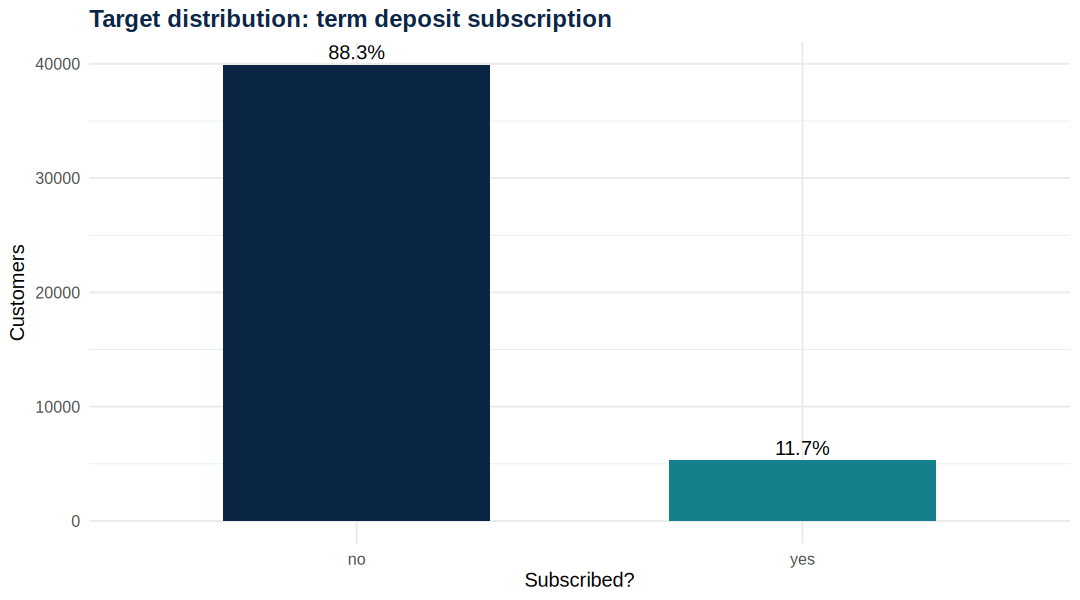

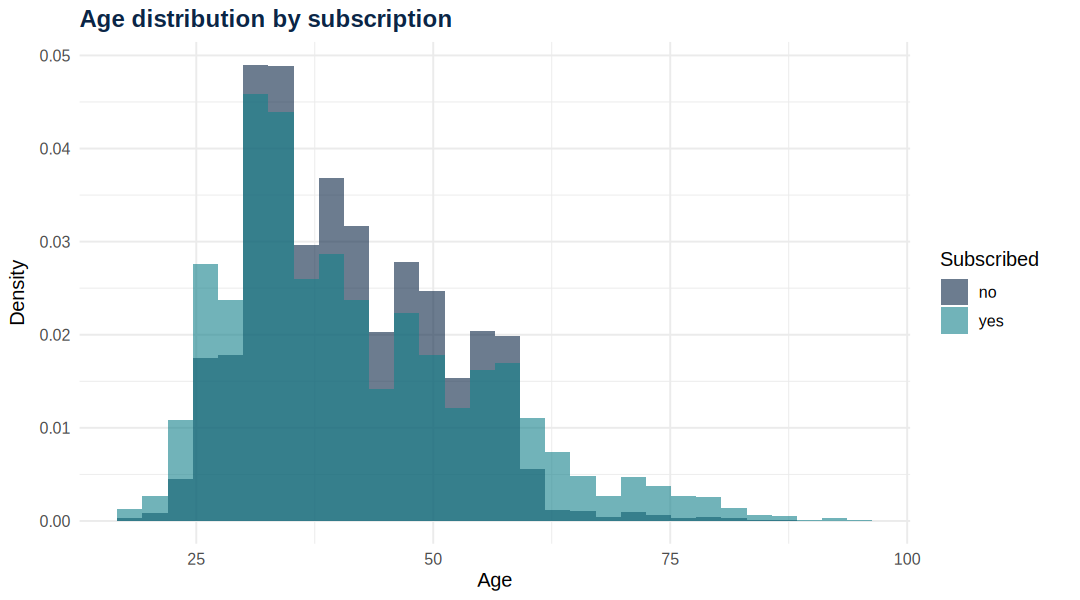

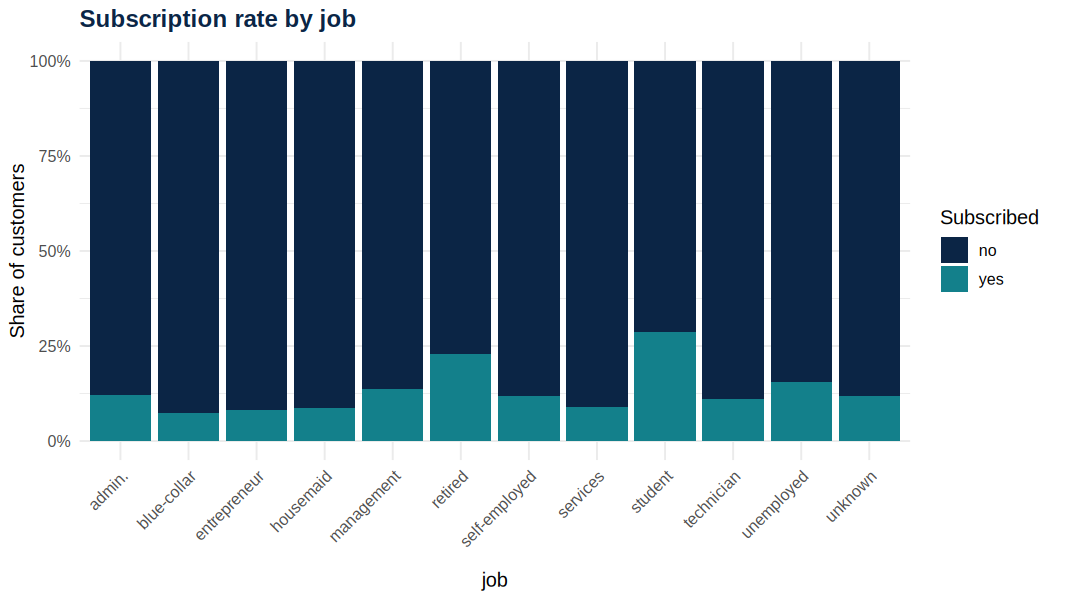

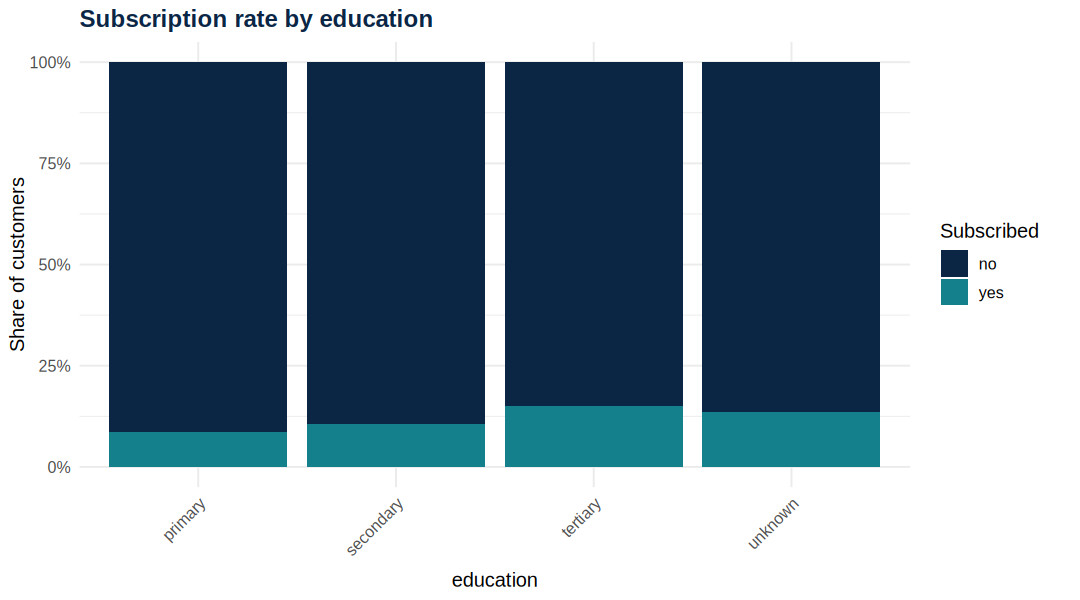

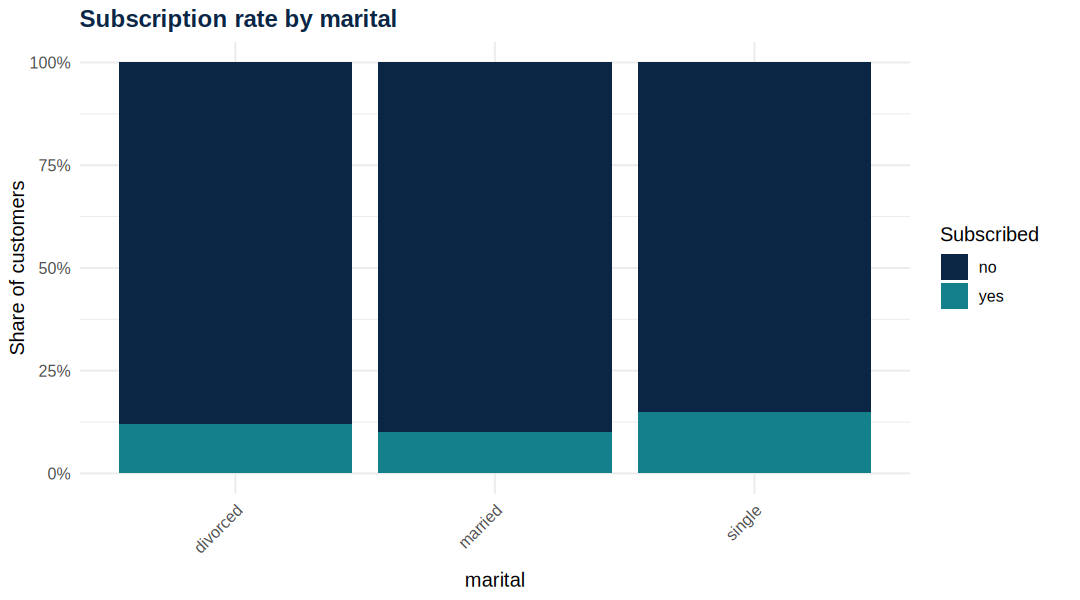

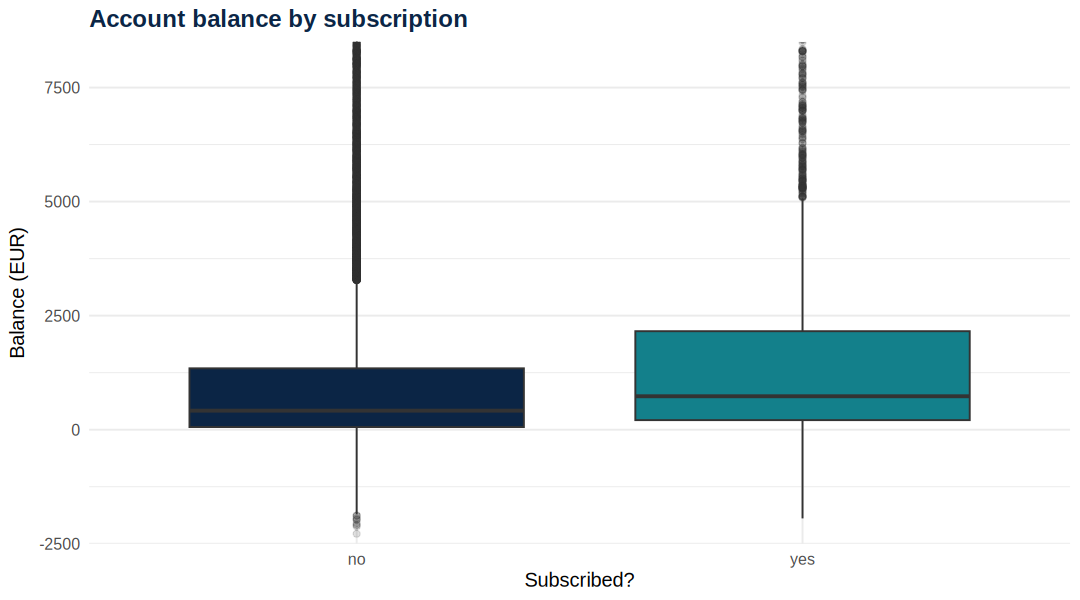

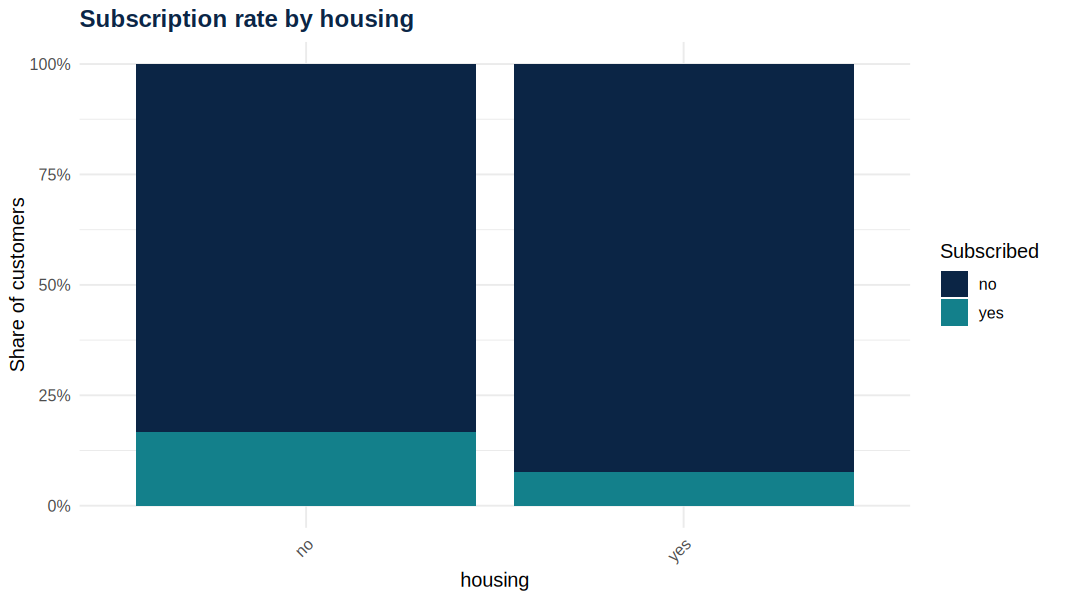

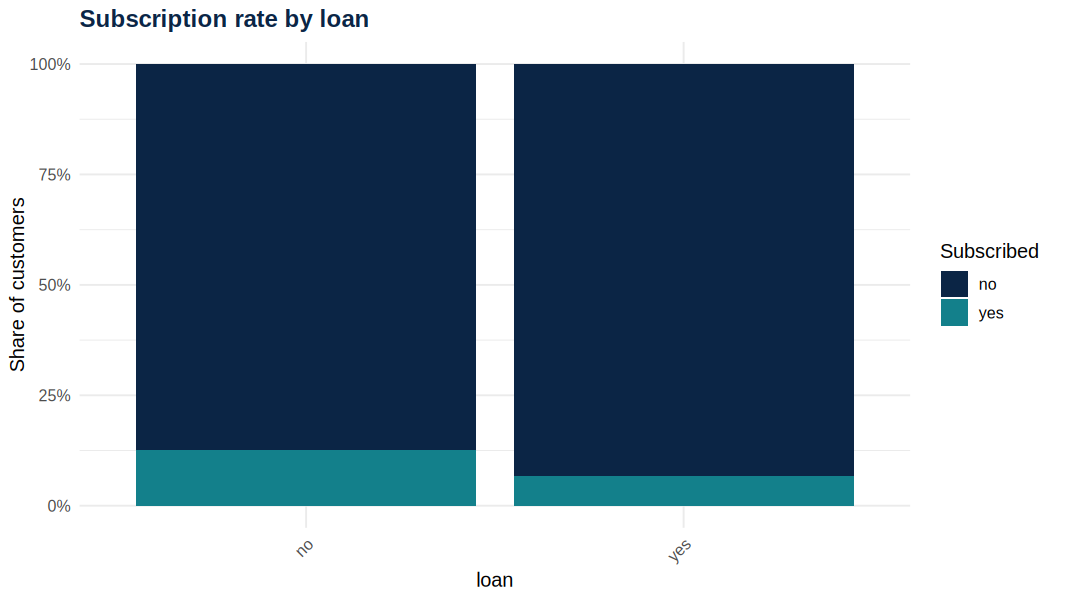

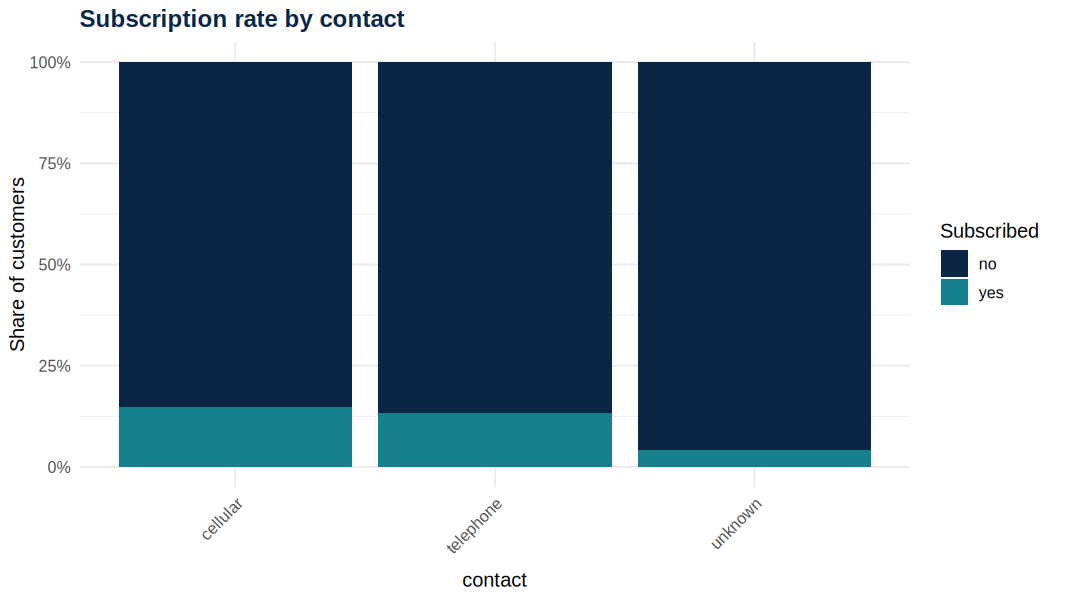

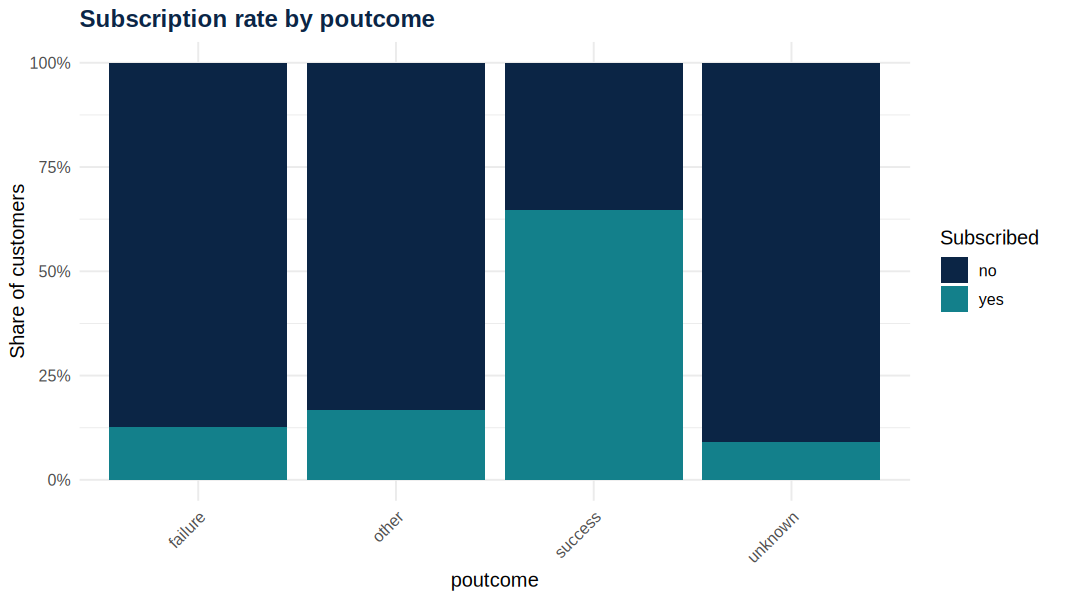

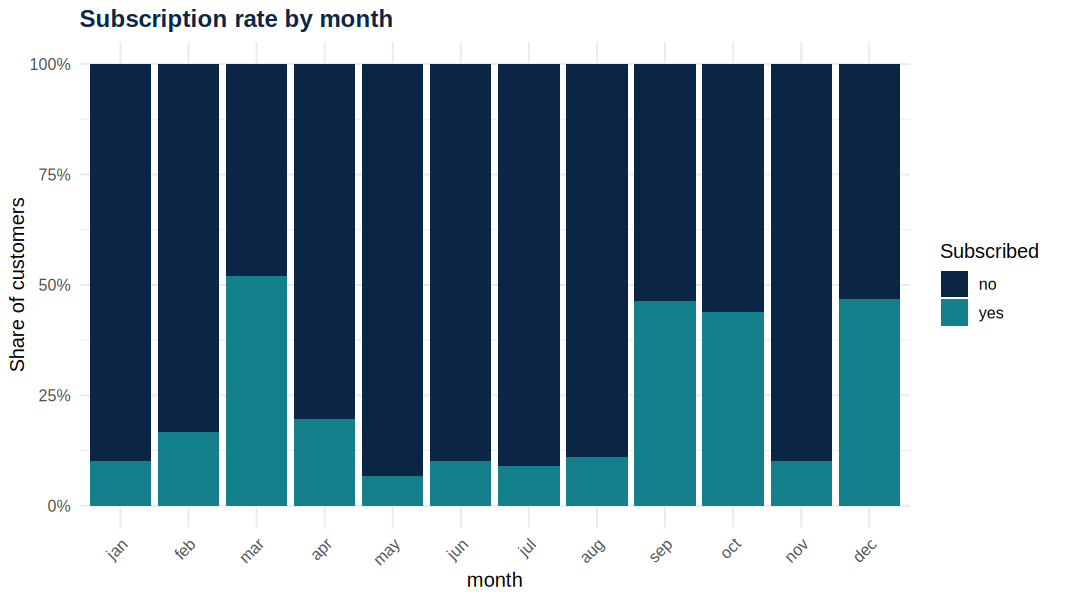

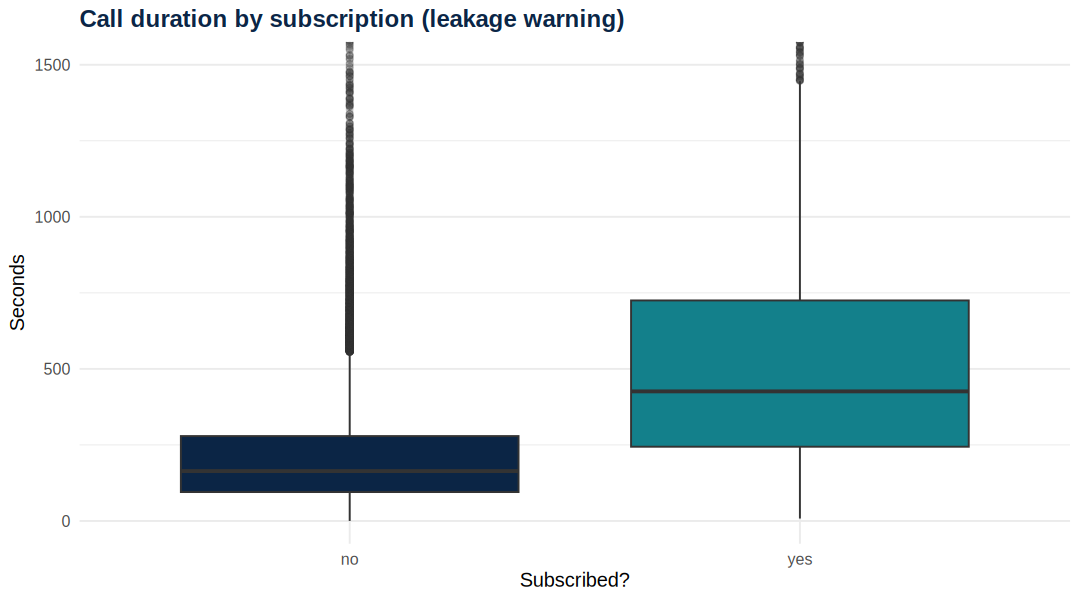

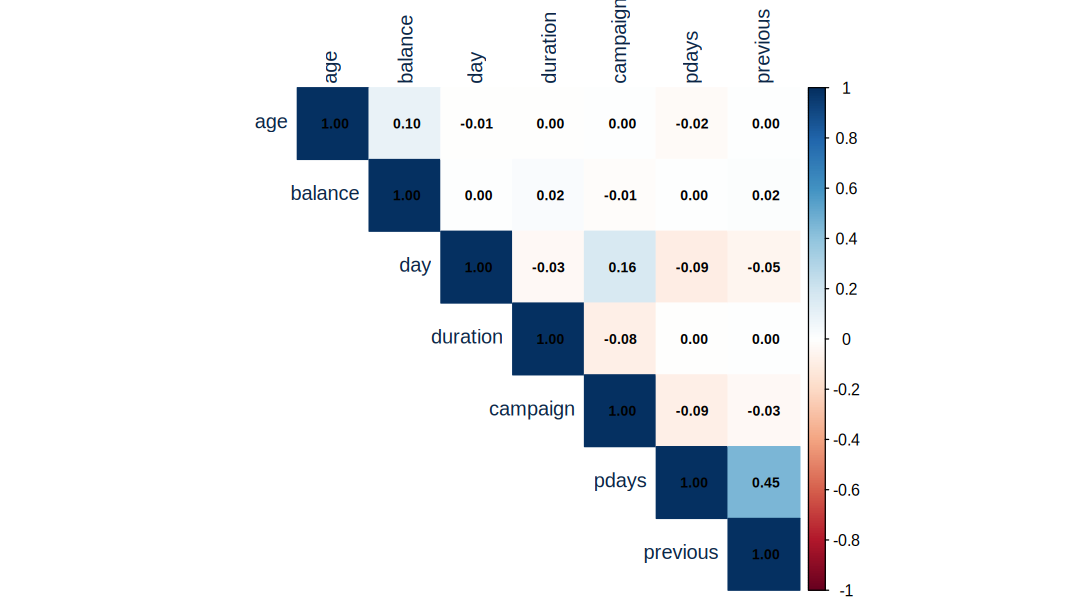

In [ ]:
navy <- "#0B2545"; teal <- "#13808B"; accent <- "#F4A261"
pal  <- c("no" = navy, "yes" = teal)

theme_bank <- theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold", colour = navy))

save_plot <- function(p, file, w = 8, h = 5) {
  ggsave(file.path("charts", file), p, width = w, height = h, dpi = 150)
  print(p)
}

prop_bar <- function(var) {
  ggplot(bank, aes(x = .data[[var]], fill = y)) +
    geom_bar(position = "fill") +
    scale_fill_manual(values = pal) +
    scale_y_continuous(labels = percent) +
    labs(title = paste("Subscription rate by", var), x = var, y = "Share of customers", fill = "Subscribed") +
    theme_bank + theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

# 1. Target distribution
target_tbl <- bank %>% count(y) %>% mutate(share = n / sum(n))
p <- ggplot(target_tbl, aes(x = y, y = n, fill = y)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = percent(share, accuracy = 0.1)), vjust = -0.4) +
  scale_fill_manual(values = pal) +
  labs(title = "Target distribution: term deposit subscription", x = "Subscribed?", y = "Customers") +
  theme_bank + theme(legend.position = "none")
save_plot(p, "01_target_distribution.png")

# 2. Age distribution
p <- ggplot(bank, aes(x = age, fill = y)) +
  geom_histogram(aes(y = after_stat(density)), bins = 30, position = "identity", alpha = 0.6) +
  scale_fill_manual(values = pal) +
  labs(title = "Age distribution by subscription", x = "Age", y = "Density", fill = "Subscribed") +
  theme_bank
save_plot(p, "02_age_distribution.png")

# 3-5. Job, education, marital status
save_plot(prop_bar("job"),       "03_job_vs_subscription.png",       9, 5.5)
save_plot(prop_bar("education"), "04_education_vs_subscription.png")
save_plot(prop_bar("marital"),   "05_marital_vs_subscription.png")

# 6. Balance by outcome (trimmed to hide extreme values)
p <- ggplot(bank, aes(x = y, y = balance, fill = y)) +
  geom_boxplot(outlier.alpha = 0.15) +
  coord_cartesian(ylim = c(-2000, 8000)) +
  scale_fill_manual(values = pal) +
  labs(title = "Account balance by subscription", x = "Subscribed?", y = "Balance (EUR)") +
  theme_bank + theme(legend.position = "none")
save_plot(p, "06_balance_boxplot.png")

# 7-9. Housing loan, personal loan, contact method
save_plot(prop_bar("housing"), "07_housing_loan.png")
save_plot(prop_bar("loan"),    "08_personal_loan.png")
save_plot(prop_bar("contact"), "09_contact_method.png")

# 10-11. Previous outcome and month
save_plot(prop_bar("poutcome"), "10_previous_outcome.png")
save_plot(prop_bar("month"),    "11_month.png")

# 12. Duration (leakage warning: only known AFTER the call)
p <- ggplot(bank, aes(x = y, y = duration, fill = y)) +
  geom_boxplot(outlier.alpha = 0.15) +
  coord_cartesian(ylim = c(0, 1500)) +
  scale_fill_manual(values = pal) +
  labs(title = "Call duration by subscription (leakage warning)", x = "Subscribed?", y = "Seconds") +
  theme_bank + theme(legend.position = "none")
save_plot(p, "12_duration_boxplot.png")

# 13. Correlation heatmap
num_cor <- cor(bank %>% select(where(is.numeric)))
png("charts/13_correlation_heatmap.png", width = 900, height = 700, res = 120)
corrplot(num_cor, method = "color", type = "upper", addCoef.col = "black",
         number.cex = 0.7, tl.col = navy)
invisible(dev.off())
corrplot(num_cor, method = "color", type = "upper", addCoef.col = "black",
         number.cex = 0.7, tl.col = navy)

In [ ]:
metrics_from_prob <- function(prob, actual, name, thr = 0.5) {
  pred <- factor(ifelse(prob >= thr, "yes", "no"), levels = c("no", "yes"))
  cm   <- confusionMatrix(pred, actual, positive = "yes")
  r    <- roc(actual, prob, levels = c("no", "yes"), direction = "<", quiet = TRUE)
  list(cm = cm, roc = r,
       row = data.frame(Model     = name,
                        Accuracy  = as.numeric(cm$overall["Accuracy"]),
                        Precision = as.numeric(cm$byClass["Precision"]),
                        Recall    = as.numeric(cm$byClass["Recall"]),
                        F1        = as.numeric(cm$byClass["F1"]),
                        AUC       = as.numeric(auc(r))))
}

run_experiment <- function(data, use_duration = FALSE, balance_method = "down",
                           split_p = 0.7, run_knn = TRUE, seed = 123) {

  if (!use_duration) data <- data %>% select(-duration)

  # Stratified train/test split
  set.seed(seed)
  idx   <- createDataPartition(data$y, p = split_p, list = FALSE)
  train <- data[idx, ]
  test  <- data[-idx, ]

  # Imbalance handling on TRAINING data only
  if (balance_method == "down") {
    train_bal <- downSample(x = train %>% select(-y), y = train$y, yname = "y")
  } else if (balance_method == "up") {
    train_bal <- upSample(x = train %>% select(-y), y = train$y, yname = "y")
  } else {
    train_bal <- train
  }

  # Model 1: Logistic Regression
  glm_m <- suppressWarnings(glm(y ~ ., data = train_bal, family = binomial))

  # Model 2: Decision Tree (pruned using the best complexity parameter)
  set.seed(seed)
  tree_m  <- rpart(y ~ ., data = train_bal, method = "class",
                   control = rpart.control(cp = 0.001, minsplit = 20))
  best_cp <- tree_m$cptable[which.min(tree_m$cptable[, "xerror"]), "CP"]
  tree_m  <- prune(tree_m, cp = best_cp)

  # Model 3: Random Forest
  set.seed(seed)
  rf_m <- randomForest(y ~ ., data = train_bal, ntree = 300, importance = TRUE)

  predictors <- list(
    "Logistic Regression" = function(d) suppressWarnings(as.numeric(predict(glm_m, d, type = "response"))),
    "Decision Tree"       = function(d) as.numeric(predict(tree_m, d, type = "prob")[, "yes"]),
    "Random Forest"       = function(d) as.numeric(predict(rf_m, d, type = "prob")[, "yes"])
  )

  # Model 4 (optional): KNN with dummy encoding + scaling
  if (run_knn) {
    dv    <- dummyVars(~ ., data = train_bal %>% select(-y), fullRank = TRUE)
    x_tr  <- predict(dv, train_bal %>% select(-y))
    pp    <- preProcess(x_tr, method = c("zv", "center", "scale"))
    knn_m <- knn3(predict(pp, x_tr), train_bal$y, k = 25)
    predictors[["KNN"]] <- function(d) {
      xd <- predict(pp, predict(dv, d %>% select(-any_of("y"))))
      as.numeric(predict(knn_m, xd, type = "prob")[, "yes"])
    }
  }

  probs <- lapply(predictors, function(f) f(test))
  evals <- Map(function(p, nm) metrics_from_prob(p, test$y, nm), probs, names(probs))

  list(train = train, train_bal = train_bal, test = test,
       glm = glm_m, tree = tree_m, rf = rf_m,
       predictors = predictors, probs = probs, evals = evals,
       results = bind_rows(lapply(evals, `[[`, "row")),
       use_duration = use_duration)
}
cat("Functions ready\n")

Functions ready


In [ ]:
res     <- run_experiment(bank, use_duration = FALSE)   # realistic model (main result)
res_dur <- run_experiment(bank, use_duration = TRUE)    # benchmark with call duration

cat("Training rows (before balancing):", nrow(res$train),
    " | after down-sampling:", nrow(res$train_bal),
    " | test rows:", nrow(res$test), "\n")
cat("Test class ratio:\n"); print(round(prop.table(table(res$test$y)), 4))

Training rows (before balancing): 31649  | after down-sampling: 7406  | test rows: 13562 
Test class ratio:

    no    yes 
0.8831 0.1169 


MAIN RESULTS (without duration, realistic model)
                Model Accuracy Precision Recall    F1   AUC
1 Logistic Regression    0.746     0.256  0.617 0.362 0.757
2       Decision Tree    0.750     0.267  0.652 0.379 0.762
3       Random Forest    0.769     0.288  0.666 0.402 0.783
4                 KNN    0.774     0.277  0.581 0.375 0.738

BENCHMARK (with duration, uses information only known after the call)
                Model Accuracy Precision Recall    F1   AUC
1 Logistic Regression    0.843     0.413  0.820 0.549 0.912
2       Decision Tree    0.839     0.412  0.876 0.561 0.903
3       Random Forest    0.839     0.414  0.916 0.570 0.931
4                 KNN    0.835     0.380  0.660 0.482 0.840

===== Logistic Regression =====
Confusion Matrix and Statistics

          Reference
Prediction   no  yes
       no  9141  608
       yes 2835  978
                                          
               Accuracy : 0.7461          
                 95% CI : (0.7387, 0.7534)
  

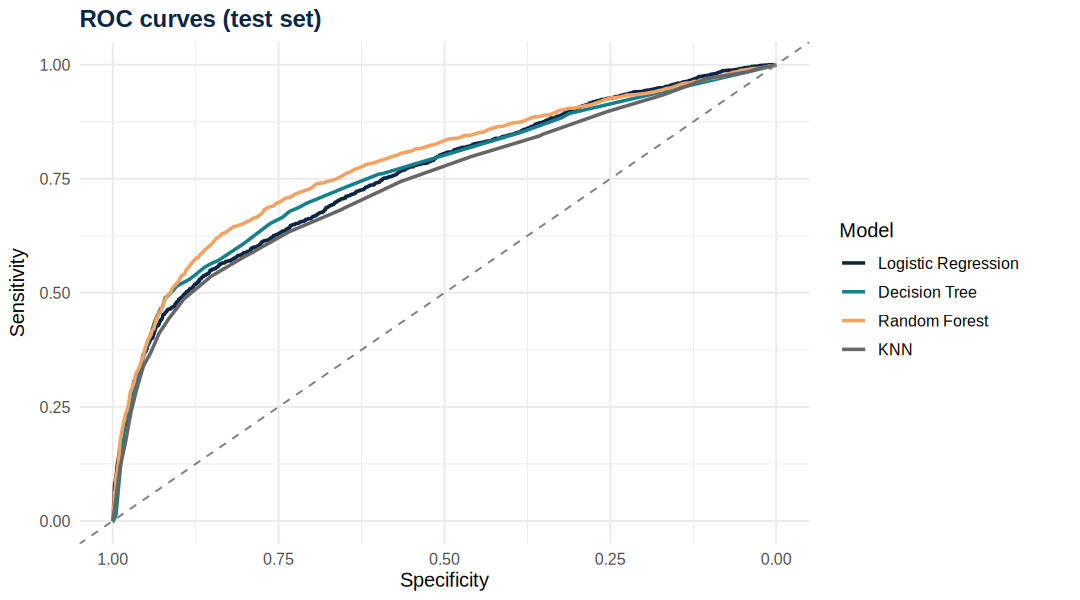

                       Version               Model    F1   AUC
1 Without duration (realistic) Logistic Regression 0.362 0.757
2 Without duration (realistic)       Decision Tree 0.379 0.762
3 Without duration (realistic)       Random Forest 0.402 0.783
4 Without duration (realistic)                 KNN 0.375 0.738
5    With duration (benchmark) Logistic Regression 0.549 0.912
6    With duration (benchmark)       Decision Tree 0.561 0.903
7    With duration (benchmark)       Random Forest 0.570 0.931
8    With duration (benchmark)                 KNN 0.482 0.840


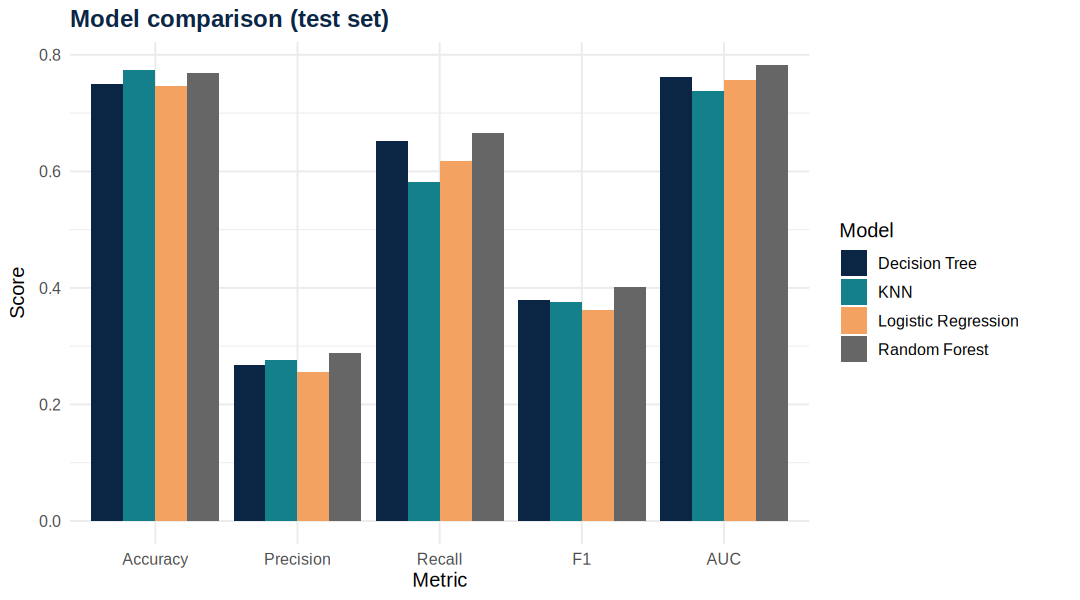

Best model (by F1, then AUC): Random Forest 


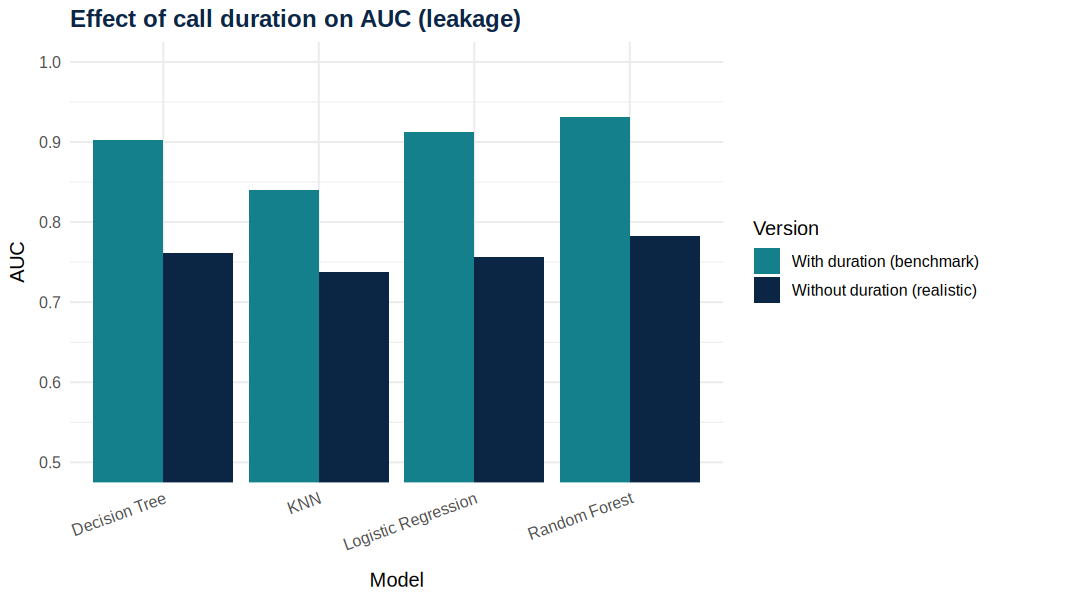

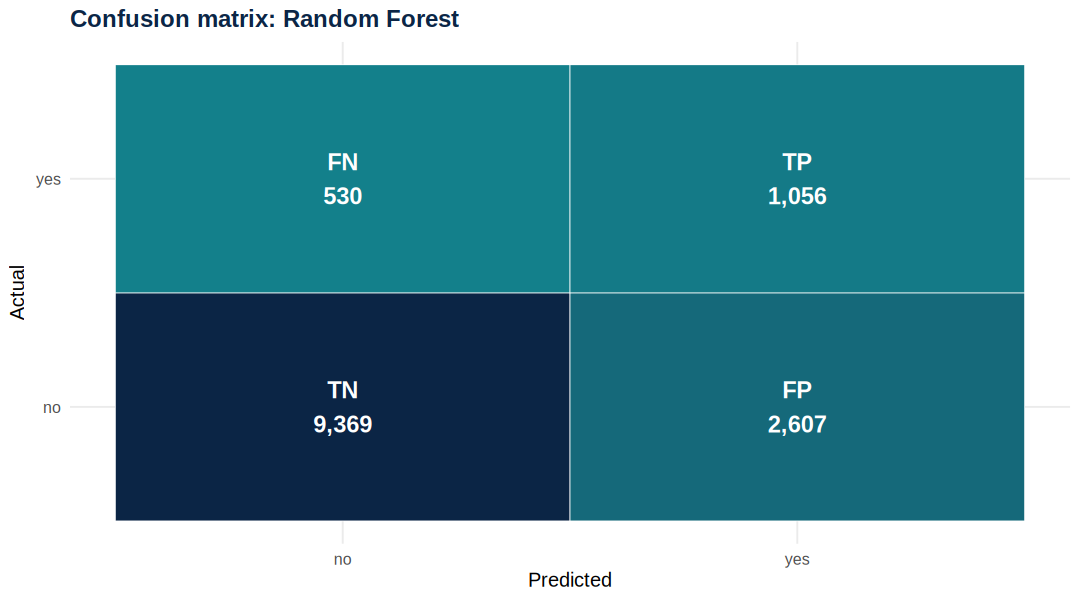

In [ ]:
results <- res$results
results[, -1] <- round(results[, -1], 3)
cat("MAIN RESULTS (without duration, realistic model)\n")
print(results)
write.csv(results, "model_comparison.csv", row.names = FALSE)

results_dur <- res_dur$results
results_dur[, -1] <- round(results_dur[, -1], 3)
cat("\nBENCHMARK (with duration, uses information only known after the call)\n")
print(results_dur)
write.csv(results_dur, "model_comparison_with_duration.csv", row.names = FALSE)

# Confusion matrix reports
for (nm in names(res$evals)) {
  cat("\n=====", nm, "=====\n")
  print(res$evals[[nm]]$cm)
}

# ROC curves
p <- ggroc(lapply(res$evals, `[[`, "roc"), linewidth = 1) +
  geom_abline(intercept = 1, slope = 1, linetype = "dashed", colour = "grey50") +
  scale_colour_manual(values = c(navy, teal, accent, "grey40")) +
  labs(title = "ROC curves (test set)", x = "Specificity", y = "Sensitivity", colour = "Model") +
  theme_bank
save_plot(p, "14_roc_curves.png")

# Metric comparison chart
p <- results %>%
  pivot_longer(-Model, names_to = "Metric", values_to = "Value") %>%
  mutate(Metric = factor(Metric, levels = c("Accuracy", "Precision", "Recall", "F1", "AUC"))) %>%
  ggplot(aes(x = Metric, y = Value, fill = Model)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c(navy, teal, accent, "grey40")) +
  labs(title = "Model comparison (test set)", y = "Score") +
  theme_bank
save_plot(p, "15_model_comparison.png")

# Effect of the duration variable (leakage)
comp <- bind_rows(
  results     %>% mutate(Version = "Without duration (realistic)"),
  results_dur %>% mutate(Version = "With duration (benchmark)")
)
print(comp %>% select(Version, Model, F1, AUC))

p <- ggplot(comp, aes(x = Model, y = AUC, fill = Version)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c(teal, navy)) +
  coord_cartesian(ylim = c(0.5, 1)) +
  labs(title = "Effect of call duration on AUC (leakage)", y = "AUC") +
  theme_bank + theme(axis.text.x = element_text(angle = 20, hjust = 1))
save_plot(p, "16_duration_leakage.png")

# Best model (F1 first, then AUC) and confusion matrix diagram
best_name <- (results %>% arrange(desc(F1), desc(AUC)))$Model[1]
cat("Best model (by F1, then AUC):", best_name, "\n")
best_eval <- res$evals[[best_name]]

cm_df <- as.data.frame(best_eval$cm$table)
cm_df$Label <- c("TN", "FP", "FN", "TP")[seq_len(nrow(cm_df))]
p <- ggplot(cm_df, aes(x = Prediction, y = Reference, fill = Freq)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = paste0(Label, "\n", comma(Freq))), colour = "white", size = 5, fontface = "bold") +
  scale_fill_gradient(low = teal, high = navy) +
  labs(title = paste("Confusion matrix:", best_name), x = "Predicted", y = "Actual") +
  theme_bank + theme(legend.position = "none")
save_plot(p, "17_confusion_matrix.png", 6, 5)

Top 3 important features: balance, month, day 


Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”
Warning message:
“labs do not fit even at cex 0.15, there may be some overplotting”
Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”
Warning message:
“labs do not fit even at cex 0.15, there may be some overplotting”


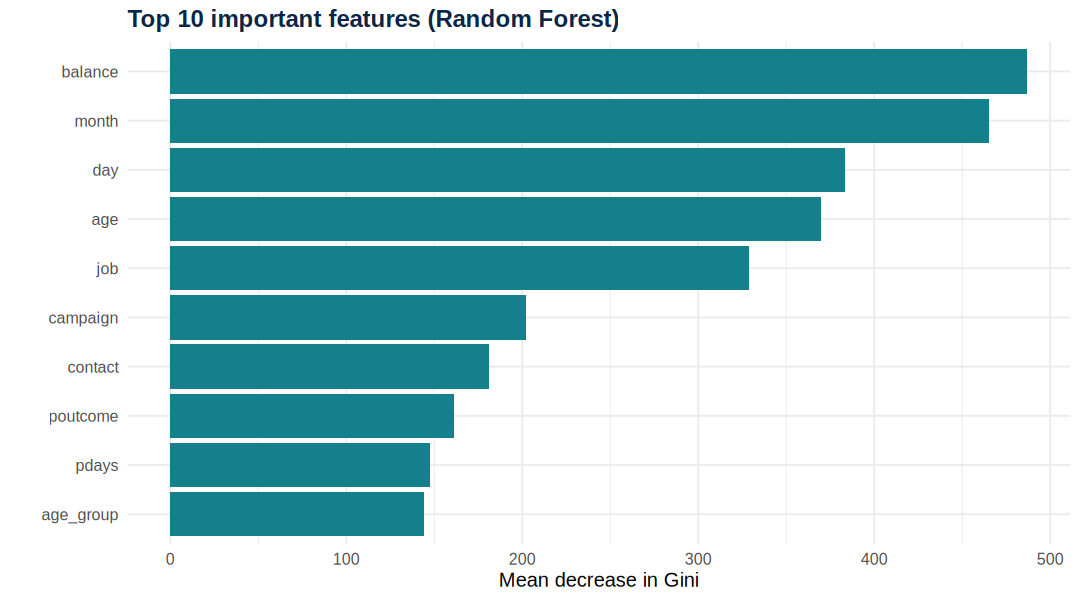

                           Variable OddsRatio PValue
monthmar                   monthmar     8.665 0.0000
poutcomesuccess     poutcomesuccess     7.876 0.0000
monthoct                   monthoct     7.048 0.0000
monthsep                   monthsep     5.099 0.0000
monthdec                   monthdec     4.428 0.0000
monthjun                   monthjun     3.045 0.0000
monthapr                   monthapr     2.939 0.0000
monthfeb                   monthfeb     2.071 0.0001
monthmay                   monthmay     1.948 0.0001
monthjul                   monthjul     1.606 0.0048
monthnov                   monthnov     1.422 0.0447
educationtertiary educationtertiary     1.382 0.0030
balance                     balance     1.000 0.0097
campaign                   campaign     0.923 0.0000
contacttelephone   contacttelephone     0.778 0.0209
maritalmarried       maritalmarried     0.743 0.0008
jobself-employed   jobself-employed     0.712 0.0362
loanyes                     loanyes     0.667 

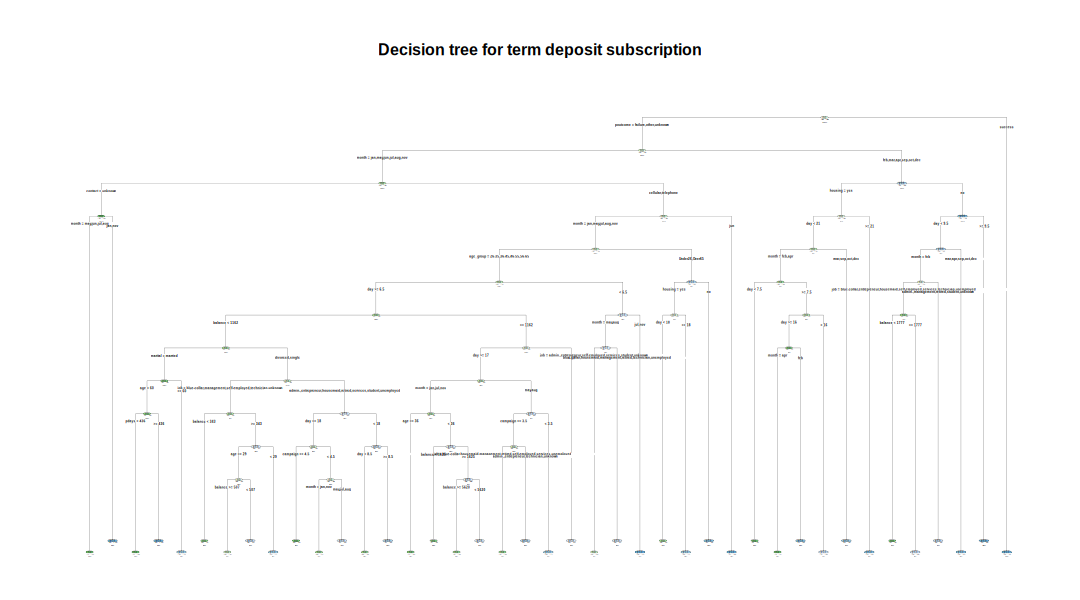

In [ ]:
# Random Forest feature importance
imp <- as.data.frame(importance(res$rf))
imp$Feature <- rownames(imp)
imp <- imp %>% arrange(desc(MeanDecreaseGini)) %>% slice_head(n = 10)

p <- ggplot(imp, aes(x = reorder(Feature, MeanDecreaseGini), y = MeanDecreaseGini)) +
  geom_col(fill = teal) + coord_flip() +
  labs(title = "Top 10 important features (Random Forest)", x = "", y = "Mean decrease in Gini") +
  theme_bank
save_plot(p, "18_feature_importance.png")
cat("Top 3 important features:", paste(head(imp$Feature, 3), collapse = ", "), "\n")

# Decision tree rules
png("charts/19_decision_tree.png", width = 1200, height = 800, res = 120)
rpart.plot(res$tree, type = 4, extra = 104, under = TRUE, box.palette = "GnBu",
           main = "Decision tree for term deposit subscription")
invisible(dev.off())
rpart.plot(res$tree, type = 4, extra = 104, under = TRUE, box.palette = "GnBu",
           main = "Decision tree for term deposit subscription")

# Logistic regression: significant odds ratios (> 1 raises the chance of subscribing)
cf <- summary(res$glm)$coefficients
odds <- data.frame(Variable  = rownames(cf),
                   OddsRatio = round(exp(cf[, "Estimate"]), 3),
                   PValue    = round(cf[, "Pr(>|z|)"], 4)) %>%
  filter(Variable != "(Intercept)", PValue < 0.05) %>%
  arrange(desc(OddsRatio))
print(odds)

  threshold sensitivity specificity
1 0.5516667    0.629256   0.8357548

At threshold 0.552 :
  Accuracy Precision Recall    F1   AUC
1    0.812     0.337  0.629 0.439 0.783
          Reference
Prediction    no   yes
       no  10009   588
       yes  1967   998
# A tibble: 10 × 5
   decile customers subscribers subscription_rate cum_pct_subscribers
    <dbl>     <int>       <int>             <dbl>               <dbl>
 1      1      1356         656             0.484               0.414
 2      2      1356         300             0.221               0.603
 3      3      1356         149             0.11                0.697
 4      4      1356         103             0.076               0.762
 5      5      1357          86             0.063               0.816
 6      6      1356          66             0.049               0.858
 7      7      1356          67             0.049               0.9  
 8      8      1356          54             0.04                0.934
 9      9      135

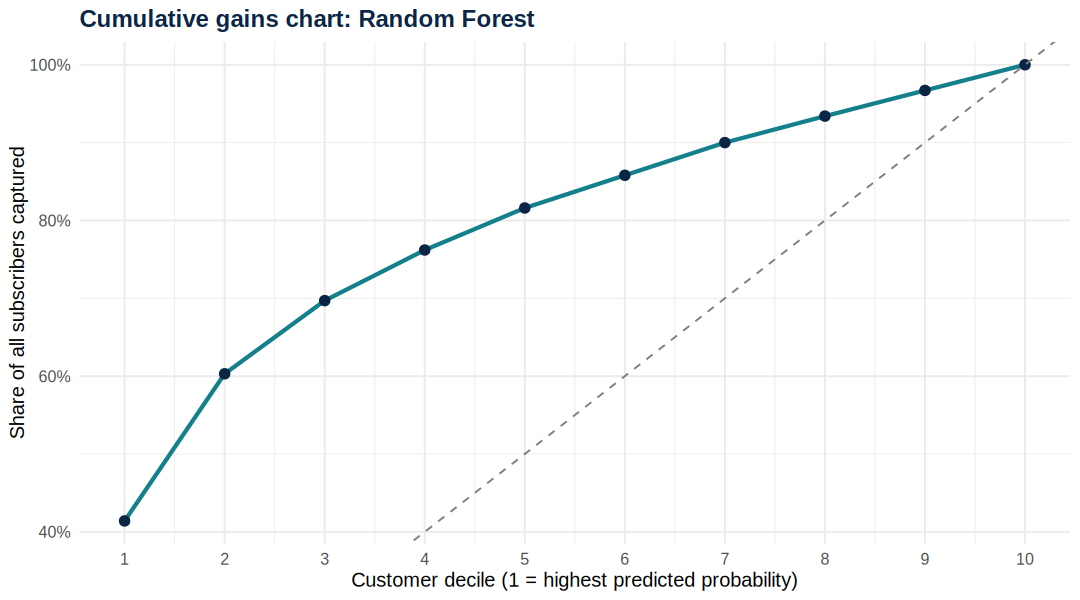

In [ ]:
# Threshold tuning (Youden's index) for the best model
best_roc  <- best_eval$roc
best_prob <- res$probs[[best_name]]

thr_tbl <- coords(best_roc, "best", best.method = "youden",
                  ret = c("threshold", "sensitivity", "specificity"))
print(thr_tbl)
best_thr <- as.numeric(thr_tbl[1, "threshold"])

tuned <- metrics_from_prob(best_prob, res$test$y, paste(best_name, "(tuned threshold)"), thr = best_thr)
cat("\nAt threshold", round(best_thr, 3), ":\n")
print(round(tuned$row[, -1], 3))
print(tuned$cm$table)

# Gains table: whom should the bank call first?
gain_tbl <- res$test %>%
  mutate(prob = best_prob) %>%
  arrange(desc(prob)) %>%
  mutate(decile = ceiling(10 * row_number() / n())) %>%
  group_by(decile) %>%
  summarise(customers = n(), subscribers = sum(y == "yes"), .groups = "drop") %>%
  mutate(subscription_rate = round(subscribers / customers, 3),
         cum_pct_subscribers = round(cumsum(subscribers) / sum(subscribers), 3))
print(gain_tbl)

p <- ggplot(gain_tbl, aes(x = decile, y = cum_pct_subscribers)) +
  geom_line(colour = teal, linewidth = 1.2) + geom_point(colour = navy, size = 2.5) +
  geom_abline(intercept = 0, slope = 0.1, linetype = "dashed", colour = "grey50") +
  scale_x_continuous(breaks = 1:10) + scale_y_continuous(labels = percent) +
  labs(title = paste("Cumulative gains chart:", best_name),
       x = "Customer decile (1 = highest predicted probability)",
       y = "Share of all subscribers captured") +
  theme_bank
save_plot(p, "20_gains_chart.png")

cat(sprintf("\nCalling only the top 30%% of customers captures about %.0f%% of all subscribers.\n",
            100 * gain_tbl$cum_pct_subscribers[3]))

# Subscription prediction demo (Yes/No + probability)
set.seed(7)
demo <- res$test[sample(nrow(res$test), 10), ]
demo_prob <- res$predictors[[best_name]](demo)

demo_out <- data.frame(
  age = demo$age, job = demo$job, balance = demo$balance,
  poutcome = demo$poutcome,
  Probability_Yes = round(demo_prob, 3),
  Prediction = ifelse(demo_prob >= best_thr, "Yes: call first", "No: low priority"),
  Actual = demo$y
)
print(demo_out)

# Summary for your slides (fills the placeholders)
best_row <- results[results$Model == best_name, ]

cat("\n---------- SLIDE 5: DATASET ----------\n")
cat("Records:", nrow(bank_raw), "| Input features:", ncol(bank_raw) - 1, "| Target: y\n")
cat("Subscribed (yes):", percent(mean(bank_raw$y == "yes"), accuracy = 0.1), "\n\n")

cat("---------- SLIDE 11: RESULTS (without duration) ----------\n")
cat("Best Model :", best_name, "\n")
cat("Accuracy   :", best_row$Accuracy, "\n")
cat("Precision  :", best_row$Precision, "\n")
cat("Recall     :", best_row$Recall, "\n")
cat("F1 Score   :", best_row$F1, "\n")
cat("ROC-AUC    :", best_row$AUC, "\n")
cat("Top 3 features:", paste(head(imp$Feature, 3), collapse = ", "), "\n")

# Zip all charts for download
zip("charts.zip", list.files("charts", full.names = TRUE), flags = "-q")
cat("\nDownload from the Files panel (left): charts.zip, model_comparison.csv, model_comparison_with_duration.csv\n")

In [ ]:
install.packages("IRdisplay")
library(IRdisplay)

display_html("<h1>Bank Marketing Analytics Dashboard</h1><p>Frontend is working!</p>")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Bank Marketing Analytics Dashboard Frontend is working!

In [ ]:

library(IRdisplay)

IRdisplay::display_html(r"---(
<div id="bank-dashboard">
<style>
#bank-dashboard{font-family:Arial,sans-serif;background:#f3f6fc;color:#172b46;border:1px solid #dce5f0;border-radius:16px;overflow:hidden}
#bank-dashboard *{box-sizing:border-box}
#bank-dashboard .layout{display:grid;grid-template-columns:210px minmax(0,1fr);min-height:650px}
#bank-dashboard .sidebar{background:#102641;color:white;padding:22px 13px}
#bank-dashboard .brand{font-size:20px;font-weight:bold;padding:5px 8px 25px}
#bank-dashboard .brand small{display:block;color:#9fb5d0;font-size:11px;margin-top:7px}
#bank-dashboard .nav{display:block;width:100%;text-align:left;padding:12px;margin:4px 0;border:0;border-radius:8px;background:transparent;color:#c9d8ea;cursor:pointer;font-size:13px}
#bank-dashboard .nav.active,#bank-dashboard .nav:hover{background:#254665;color:white}
#bank-dashboard .content{padding:24px;min-width:0}
#bank-dashboard h1{font-size:25px;margin:0 0 8px}
#bank-dashboard h2{font-size:17px;margin:0 0 15px}
#bank-dashboard .subtitle{font-size:12px;color:#718198;margin-bottom:23px}
#bank-dashboard .cards{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:12px}
#bank-dashboard .columns{display:grid;grid-template-columns:1fr 1fr;gap:14px}
#bank-dashboard .card{background:white;border:1px solid #e1e8f1;border-radius:12px;padding:18px;margin-bottom:14px;min-width:0}
#bank-dashboard .label{font-size:12px;color:#738198}
#bank-dashboard .number{font-size:25px;font-weight:bold;margin-top:10px;color:#142b47}
#bank-dashboard .hint{font-size:11px;color:#8491a5;margin-top:6px}
#bank-dashboard .page{display:none}
#bank-dashboard .page.active{display:block}
#bank-dashboard label{display:block;font-size:13px;margin:13px 0 7px;color:#607087}
#bank-dashboard input,#bank-dashboard select{width:100%;padding:12px;border:1px solid #d9e2ed;border-radius:7px;background:white;font-size:14px}
#bank-dashboard .formgrid{display:grid;grid-template-columns:1fr 1fr;gap:12px}
#bank-dashboard .btn{padding:12px 16px;border:0;border-radius:8px;background:#117e78;color:white;cursor:pointer;font-weight:bold;margin-top:18px}
#bank-dashboard .btn:hover{background:#0c625e}
#bank-dashboard .result{padding:20px;background:#f0f7ff;border:1px solid #dce8f8;border-radius:10px;margin-top:16px}
#bank-dashboard .score{font-size:42px;font-weight:bold;margin:8px 0}
#bank-dashboard .track{height:12px;border-radius:20px;background:#e9eef5;overflow:hidden;margin:12px 0}
#bank-dashboard .fill{height:100%;width:0;background:#138b83;border-radius:20px;transition:width .3s}
#bank-dashboard .warning{padding:13px;background:#fff6e5;color:#775820;border-radius:9px;font-size:12px;line-height:1.6;margin-top:12px}
#bank-dashboard .info{font-size:13px;line-height:1.8;color:#607087}
#bank-dashboard .pill{display:inline-block;padding:7px 11px;border-radius:20px;background:#e5effb;color:#244d78;font-size:12px;font-weight:bold}
#bank-dashboard table{width:100%;border-collapse:collapse;font-size:13px}
#bank-dashboard th,#bank-dashboard td{text-align:left;padding:12px 7px;border-bottom:1px solid #e8edf4}
#bank-dashboard th{color:#738198}
@media(max-width:750px){#bank-dashboard .layout{grid-template-columns:1fr}#bank-dashboard .sidebar{padding:12px}#bank-dashboard .nav{display:inline-block;width:auto}#bank-dashboard .content{padding:13px}#bank-dashboard .columns{grid-template-columns:1fr}#bank-dashboard .cards{grid-template-columns:1fr}#bank-dashboard .formgrid{grid-template-columns:1fr}}
</style>

<div class="layout">
<aside class="sidebar">
  <div class="brand">◈ Bank Insights<small>MARKETING ANALYTICS</small></div>
  <button class="nav active" data-page="overview">▦ Overview</button>
  <button class="nav" data-page="explore">▤ Risk Factors</button>
  <button class="nav" data-page="predict">◎ Customer Risk Prediction</button>
  <button class="nav" data-page="models">⌁ Model Information</button>
  <div style="margin:35px 8px;color:#9fb5d0;font-size:11px;line-height:1.8">
    IDS CASE STUDY<br><b>Term Deposit Analytics</b><br>Machine Learning in R
  </div>
</aside>

<main class="content">
  <h1 id="bd-title">Overview</h1>
  <div class="subtitle">Bank Marketing Analytics — Customer Risk Assessment</div>

  <section class="page active" id="bd-overview">
    <div class="cards">
      <div class="card"><div class="label">Dataset reference</div><div class="number">45,211</div><div class="hint">Records in Bank Marketing full dataset</div></div>
      <div class="card"><div class="label">Risk inputs</div><div class="number">3</div><div class="hint">Age, balance and existing loan</div></div>
      <div class="card"><div class="label">Assessment</div><div class="number">Risk score</div><div class="hint">Illustrative screening only</div></div>
    </div>
    <div class="columns">
      <div class="card">
        <h2>Project Objective</h2>
        <p class="info">Assess customer information to support bank marketing decisions and explore which customer characteristics may be associated with subscription outcomes.</p>
      </div>
      <div class="card">
        <h2>Workflow</h2>
        <p class="info">1. Collect customer data</p>
        <p class="info">2. Validate and preprocess data</p>
        <p class="info">3. Train and evaluate an R model</p>
        <p class="info">4. Generate and interpret predictions</p>
      </div>
    </div>
    <div class="warning"><b>Important:</b> The score in this frontend is a rule-based demonstration. It is not trained on the Bank Marketing dataset and must not be treated as a validated prediction.</div>
  </section>

  <section class="page" id="bd-explore">
    <div class="card">
      <h2>Factors Used in This Demonstration</h2>
      <table>
        <tr><th>Input</th><th>Interpretation</th></tr>
        <tr><td>Age</td><td>Customer's age in years</td></tr>
        <tr><td>Bank balance</td><td>Account balance; currency depends on the dataset</td></tr>
        <tr><td>Existing personal loan</td><td>Whether the customer has a personal loan</td></tr>
      </table>
      <p class="info">These variables alone do not establish a customer's true financial risk or likelihood of subscribing to a term deposit. Their relationship with the outcome must be learned and validated from historical data.</p>
    </div>
  </section>

  <section class="page" id="bd-predict">
    <div class="columns">
      <div class="card">
        <h2>Customer Details</h2>
        <div class="formgrid">
          <div>
            <label for="bd-age">Age (years)</label>
            <input id="bd-age" type="number" min="18" max="100" value="35">
          </div>
          <div>
            <label for="bd-balance">Bank balance</label>
            <input id="bd-balance" type="number" value="2500">
          </div>
          <div style="grid-column:1/-1">
            <label for="bd-loan">Existing personal loan?</label>
            <select id="bd-loan">
              <option value="no">No</option>
              <option value="yes">Yes</option>
              <option value="unknown">Unknown</option>
            </select>
          </div>
        </div>
        <button class="btn" id="bd-run">Calculate Demonstration Score</button>
      </div>

      <div class="card">
        <h2>Customer Risk Assessment</h2>
        <p class="info">Enter the three customer details and calculate the illustrative score.</p>
        <div class="result" id="bd-result" aria-live="polite">
          <div class="label">Illustrative risk index</div>
          <div class="score" id="bd-score">--%</div>
          <span class="pill" id="bd-category">Awaiting input</span>
          <div class="track"><div class="fill" id="bd-fill"></div></div>
          <p class="info" id="bd-explanation">Your assessment will appear here.</p>
          <hr style="border:0;border-top:1px solid #dce5f0;margin:16px 0">
          <div class="label">Factors considered</div>
          <p class="info" id="bd-factors">No assessment calculated yet.</p>
        </div>
        <div class="warning">This is a demonstration index, not a probability of subscription or a validated credit-risk score.</div>
      </div>
    </div>
  </section>

  <section class="page" id="bd-models">
    <div class="card">
      <h2>Model Integration Status</h2>
      <p class="info">The frontend currently uses a transparent rule-based index. It does not call a trained R model.</p>
      <table>
        <tr><th>Component</th><th>Status</th></tr>
        <tr><td>Customer input form</td><td>Available</td></tr>
        <tr><td>Illustrative score calculation</td><td>Available</td></tr>
        <tr><td>Trained model integration</td><td>Not connected</td></tr>
        <tr><td>Validated prediction metrics</td><td>Not available in this frontend</td></tr>
      </table>
      <p class="info">For actual term-deposit subscription probabilities, train a model on historical labelled data and connect the frontend to that model. Evaluate it on unseen data before reporting its performance.</p>
    </div>
  </section>
</main>
</div>

<script>
(function(){
  const root = document.getElementById('bank-dashboard');
  if (!root) return;

  const titles = {
    overview: 'Overview',
    explore: 'Risk Factors',
    predict: 'Customer Risk Prediction',
    models: 'Model Information'
  };

  root.querySelectorAll('.nav').forEach(function(button){
    button.addEventListener('click', function(){
      root.querySelectorAll('.nav').forEach(function(b){b.classList.remove('active');});
      root.querySelectorAll('.page').forEach(function(p){p.classList.remove('active');});
      button.classList.add('active');
      root.querySelector('#bd-' + button.dataset.page).classList.add('active');
      root.querySelector('#bd-title').textContent = titles[button.dataset.page];
    });
  });

  root.querySelector('#bd-run').addEventListener('click', function(){
    const ageInput = root.querySelector('#bd-age');
    const balanceInput = root.querySelector('#bd-balance');
    const loanInput = root.querySelector('#bd-loan');

    const age = Number(ageInput.value);
    const balance = Number(balanceInput.value);

    if (!ageInput.value || !balanceInput.value ||
        !Number.isFinite(age) || !Number.isFinite(balance) ||
        age < 18 || age > 100) {
      alert('Enter a valid age between 18 and 100 and a valid bank balance.');
      return;
    }

    const loan = loanInput.value;

    // Transparent heuristic for demonstration only.
    // Weights are illustrative and are NOT learned from data.
    let score = 40;
    const factors = [];

    if (age < 25) {
      score += 8;
      factors.push('Age below 25: +8 index points');
    } else if (age > 60) {
      score += 5;
      factors.push('Age above 60: +5 index points');
    } else {
      factors.push('Age 25–60: no age adjustment');
    }

    if (balance < 0) {
      score += 20;
      factors.push('Negative balance: +20 index points');
    } else if (balance < 500) {
      score += 12;
      factors.push('Balance below 500: +12 index points');
    } else if (balance < 2000) {
      score += 5;
      factors.push('Balance 500–1999: +5 index points');
    } else {
      score -= 5;
      factors.push('Balance 2000 or higher: −5 index points');
    }

    if (loan === 'yes') {
      score += 10;
      factors.push('Existing personal loan: +10 index points');
    } else if (loan === 'no') {
      factors.push('No existing personal loan: no adjustment');
    } else {
      score += 5;
      factors.push('Loan status unknown: +5 index points');
    }

    score = Math.max(0, Math.min(100, score));

    let category, explanation, color;
    if (score < 35) {
      category = 'Lower illustrative index';
      explanation = 'The chosen demonstration rules produce a lower index. This does not establish a low probability of subscribing.';
      color = '#138b83';
    } else if (score < 65) {
      category = 'Moderate illustrative index';
      explanation = 'The chosen demonstration rules produce a moderate index. A trained model is required for a reliable subscription probability.';
      color = '#d69b26';
    } else {
      category = 'Higher illustrative index';
      explanation = 'The chosen demonstration rules produce a higher index. This does not mean the customer will or will not subscribe.';
      color = '#d65b5b';
    }

    root.querySelector('#bd-result').style.display = 'block';
    root.querySelector('#bd-score').textContent = score.toFixed(0) + '%';
    root.querySelector('#bd-category').textContent = category;
    root.querySelector('#bd-category').style.background = color + '20';
    root.querySelector('#bd-category').style.color = color;
    root.querySelector('#bd-fill').style.width = score + '%';
    root.querySelector('#bd-fill').style.background = color;
    root.querySelector('#bd-explanation').textContent = explanation;
    root.querySelector('#bd-factors').textContent = factors.join(' · ');
  });
})();
</script>
</div>
)---")


Input,Interpretation
Age,Customer's age in years
Bank balance,Account balance; currency depends on the dataset
Existing personal loan,Whether the customer has a personal loan
Component,Status
Customer input form,Available
Illustrative score calculation,Available
Trained model integration,Not connected
Validated prediction metrics,Not available in this frontend
